# 모델 비교

- 베이스라인 + **채택한 모델**(`ADOPTED`)의 `results/<모델명>/per_pitch.parquet`만 읽어 같은 기준으로 비교 → 새 모델을 채택하면 `ADOPTED`에 추가
  - 채택 안 한 모델(model_04 등)은 결과 폴더가 있어도 넣지 않음 -> 결과는 각 노트북과 README 4장 (채택X)
- 채점 함수는 전부 `fp_common.py` (베이스라인 노트북과 같은 방식)
- 평가 2020, 재보정 학습 2019
- 모델 폴더 이름은 영어로

새 모델 노트북에서 저장하는 방법 (열 규칙은 `fp_common.py` 맨 위 설명)
```python
import fp_common as fc
m, names = fc.load_data()
fp, y_type, y_zone, val, test = fc.first_pitches(m)
# ... 모델 학습·예측 (2019 검증 + 2020 평가 초구 전부) ...
pp = pd.concat([fp.loc[val | test, fc.KEYS].reset_index(drop=True),
                pd.DataFrame(P_type, columns=fc.P_TYPE),    # 구종 확률 9개
                pd.DataFrame(P_zone, columns=fc.P_ZONE)],   # 실전 24칸 확률
               axis=1)
fc.save_results("model_01_lgbm", pp, {"summary_2020": summary})  # results/model_01_lgbm/
```

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fp_common as fc

m, names = fc.load_data()
fp, y_type, y_zone, val, test = fc.first_pitches(m)
ADOPTED = ["model_01", "model_02", "model_03", "model_05", "model_06", "model_07", "model_09", "model_11", "model_12", "model_13", "model_14", "model_16", "model_18", "model_20"]  # 채택한 모델, 새 모델을 채택하면 여기에 추가 (채택 안 한 모델은 README 4장 제목에 (채택X))
R = fc.load_results(["baseline"] + ADOPTED)  # 베이스라인 + 채택한 모델만
assert list(R) == ["baseline"] + ADOPTED, f"결과 파일 없는 모델: {set(ADOPTED) - set(R)}"
mark = lambda n: ""  # 채택한 모델만 읽으므로 표시 없음 (예전 (채택X) 표시 자리)
print("모델:", list(R))

모델: ['baseline', 'model_01', 'model_02', 'model_03', 'model_05', 'model_06', 'model_07', 'model_09', 'model_11', 'model_12', 'model_13', 'model_14', 'model_16', 'model_18', 'model_20']


## 0. 베이스라인 재현 확인

`fp_common`으로 채점한 베이스라인 값이 베이스라인 노트북 요약(`results/baseline/*.csv`)과 같은지 → 같으면 두 곳의 채점 방식이 일치

In [2]:
base = fc.evaluate(R["baseline"], fp)
summ = pd.read_csv("results/baseline/summary_2020.csv", index_col=0)
true_row = [r for r in summ.index if r.startswith("② 위치 24칸 · 실제 구종")][0]
expect = {"구종 logloss": summ.loc["① 구종 (B4)", "logloss"],
          "구종 top1": summ.loc["① 구종 (B4)", "top1"],
          "24칸 logloss (실전)": summ.loc["② 위치 24칸 · 예측 구종 (실전)", "logloss"],
          "24칸 logloss (실제 구종)": summ.loc[true_row, "logloss"],
          "H/S/C 정확도": summ.loc["② 위치 24칸 · 예측 구종 (실전)", "H/S/C 정확도"],
          "구종×칸 logloss": summ.loc["구종×칸 동시 (실전, 216가지)", "logloss"],
          "좌표 평균거리 cm": summ.loc["② 위치 좌표 · 예측 구종 (실전)", "평균거리 cm"],
          "좌표 NLL": summ.loc["② 위치 좌표 · 예측 구종 (실전)", "NLL"]}
chk = pd.DataFrame({"베이스라인 노트북": expect, "fp_common": {k: base[k] for k in expect}})
chk["같음"] = np.isclose(chk["베이스라인 노트북"], chk["fp_common"], rtol=1e-6)
display(chk.round(4))
assert chk["같음"].all(), "fp_common 채점이 베이스라인 노트북과 다름"

,베이스라인 노트북,fp_common,같음
구종 logloss,1.1018,1.1018,True
구종 top1,0.5244,0.5244,True
24칸 logloss (실전),2.9791,2.9791,True
24칸 logloss (실제 구종),2.9403,2.9403,True
H/S/C 정확도,0.3883,0.3883,True
구종×칸 logloss,4.0419,4.0419,True
좌표 평균거리 cm,31.9869,31.9869,True
좌표 NLL,9.2882,9.2882,True


## 1. 요약 (2020)

- 작을수록 good: logloss, NLL, 거리
- 클수록 good: top-k, macro F1, 정확도
- 선택 열이 없는 모델은 그 지표가 빈칸

In [3]:
summary = pd.DataFrame({n: fc.evaluate(pp, fp) for n, pp in R.items()}).T
display(summary.rename(index=lambda n: n + mark(n)).round(4))  # 채택 안 한 모델은 (채택X)
summary.to_csv(fc.RESULTS_DIR + "/compare_summary_2020.csv", encoding="utf-8-sig")

,구종 logloss,구종 top1,구종 top2,구종 top3,구종 macro F1,24칸 logloss (실전),24칸 top1,24칸 top3,H/S/C logloss,H/S/C 정확도,24칸 logloss (실제 구종),구종×칸 logloss,좌표 평균거리 cm,좌표 NLL
baseline,1.1018,0.5244,0.8111,0.9324,0.2576,2.9791,0.1328,0.2828,1.0800,0.3883,2.9403,4.0419,31.9869,9.2882
model_01,1.0956,0.5233,0.8162,0.9359,0.2857,2.9708,0.1339,0.2850,1.0783,0.3902,2.9226,4.0182,31.9009,9.2708
model_02,1.0956,0.5233,0.8162,0.9359,0.2857,2.9698,0.1331,0.2859,1.0778,0.3874,2.9225,4.0177,31.8840,9.2689
model_03,1.0956,0.5233,0.8162,0.9359,0.2857,2.9479,0.1330,0.2897,1.0772,0.3885,2.8967,3.9916,31.8837,9.2690
model_05,1.0610,0.5306,0.8207,0.9387,0.3361,2.9455,0.1338,0.2906,1.0767,0.3889,2.8967,3.9569,31.8324,9.2660
model_06,1.0574,0.5330,0.8203,0.9409,0.3496,2.9457,0.1339,0.2913,1.0768,0.3883,2.8967,3.9534,31.8351,9.2663
model_07,1.0570,0.5340,0.8209,0.9413,0.3510,2.9456,0.1340,0.2912,1.0767,0.3891,2.8967,3.9530,31.8346,9.2662
model_09,1.0561,0.5332,0.8218,0.9412,0.3545,2.9454,0.1337,0.2908,1.0767,0.3896,2.8967,3.9521,31.8305,9.2660
model_11,1.0561,0.5332,0.8218,0.9412,0.3545,2.9453,0.1331,0.2920,1.0765,0.3898,2.8963,3.9518,31.8253,9.2661
model_12,1.0561,0.5332,0.8218,0.9412,0.3545,2.9448,0.1321,0.2917,1.0765,0.3910,2.8934,3.9489,31.8177,9.2657


## 2. 베이스라인 대비 차이 (경기 단위 부트스트랩)

- 공별 점수 차이 (모델 − 베이스라인) → 음수면 good
- 경기를 중복 허용하여 1,000번 다시 뽑아 95% 구간 → 구간이 0을 넘지 않으면 확실한 차이
- 점수: `ll_type` 구종, `ll_zone` 24칸(실전), `ll_joint` 구종×칸, `nll_coord`·`dist` 좌표 / 두 모델 모두 있는 열만

In [4]:
S = {n: fc.pitch_scores(pp, fp) for n, pp in R.items()}  # 공별 점수 (2020)
others = [n for n in R if n != "baseline"]
if not others:
    print("비교할 모델 없음")
for n in others:
    print(n, "− baseline")
    display(fc.bootstrap_diff(S["baseline"], S[n]).round(4))

model_01 − baseline


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,-0.0062,-0.0101,-0.0030,좋아짐
ll_zone,-0.0082,-0.0110,-0.0057,좋아짐
ll_hsc,-0.0017,-0.0027,-0.0007,좋아짐
ll_joint,-0.0237,-0.0297,-0.0182,좋아짐
nll_coord,-0.0174,-0.0210,-0.0139,좋아짐
dist,-0.0860,-0.1335,-0.0411,좋아짐


model_02 − baseline


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,-0.0062,-0.0101,-0.0030,좋아짐
ll_zone,-0.0093,-0.0121,-0.0066,좋아짐
ll_hsc,-0.0022,-0.0033,-0.0011,좋아짐
ll_joint,-0.0242,-0.0315,-0.0175,좋아짐
nll_coord,-0.0193,-0.0229,-0.0156,좋아짐
dist,-0.1029,-0.1546,-0.0540,좋아짐


model_03 − baseline


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,-0.0062,-0.0101,-0.0030,좋아짐
ll_zone,-0.0312,-0.0361,-0.0261,좋아짐
ll_hsc,-0.0028,-0.0042,-0.0015,좋아짐
ll_joint,-0.0503,-0.0586,-0.0427,좋아짐
nll_coord,-0.0192,-0.0229,-0.0154,좋아짐
dist,-0.1032,-0.1548,-0.0546,좋아짐


... (18 outputs left out)

model_18 − baseline


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,-0.0457,-0.0541,-0.0384,좋아짐
ll_zone,-0.0525,-0.0592,-0.0460,좋아짐
ll_hsc,-0.0072,-0.0093,-0.0050,좋아짐
ll_joint,-0.1155,-0.1291,-0.1032,좋아짐
nll_coord,-0.0389,-0.0447,-0.0333,좋아짐
dist,-0.3550,-0.4339,-0.2748,좋아짐


model_20 − baseline


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,-0.0457,-0.0541,-0.0384,좋아짐
ll_zone,-0.0533,-0.0602,-0.0466,좋아짐
ll_hsc,-0.0072,-0.0095,-0.0050,좋아짐
ll_joint,-0.1164,-0.1297,-0.1040,좋아짐
nll_coord,-0.0452,-0.0512,-0.0393,좋아짐
dist,-0.4114,-0.4984,-0.3264,좋아짐


### 2-1. 직전 채택 모델 대비 (경기 단위 부트스트랩)

- 공별 점수 차이 (모델 − 직전 채택 모델) → 음수면 good, 판정 방식은 위와 같음
- 직전 채택 모델 = 이 모델 앞 번호 중 가장 최근에 채택한 모델 (`ADOPTED`)
  - 예: model_04·model_08는 채택X라 표에 없음 → model_05는 model_03과, model_09은 model_07과 비교
- 각 모델이 직전 채택 모델 위에 한 가지만 바꾼 효과 확인용 -> 새 모델 채택 판단은 이 표로

In [5]:
for i, n in enumerate(others):
    prev = next((p for p in reversed(others[:i]) if p in ADOPTED), "baseline")  # 이 모델 앞에서 가장 최근에 채택한 모델 (없으면 베이스라인)
    if prev == "baseline":
        continue  # 베이스라인 대비는 위 표
    print(n + mark(n), "−", prev + mark(prev))
    display(fc.bootstrap_diff(S[prev], S[n]).round(4))

model_02 − model_01


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,0.0000,0.0000,0.0000,차이 불확실
ll_zone,-0.0011,-0.0018,-0.0004,좋아짐
ll_hsc,-0.0005,-0.0007,-0.0002,좋아짐
ll_joint,-0.0005,-0.0033,0.0032,차이 불확실
nll_coord,-0.0019,-0.0031,-0.0007,좋아짐
dist,-0.0169,-0.0288,-0.0052,좋아짐


model_03 − model_02


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,0.0000,0.0000,0.0000,차이 불확실
ll_zone,-0.0219,-0.0258,-0.0179,좋아짐
ll_hsc,-0.0007,-0.0012,-0.0002,좋아짐
ll_joint,-0.0261,-0.0307,-0.0213,좋아짐
nll_coord,0.0000,-0.0001,0.0001,차이 불확실
dist,-0.0003,-0.0010,0.0005,차이 불확실


model_05 − model_03


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,-0.0346,-0.0386,-0.0303,좋아짐
ll_zone,-0.0024,-0.0035,-0.0012,좋아짐
ll_hsc,-0.0005,-0.0008,-0.0001,좋아짐
ll_joint,-0.0346,-0.0386,-0.0303,좋아짐
nll_coord,-0.0029,-0.0042,-0.0016,좋아짐
dist,-0.0512,-0.0731,-0.0277,좋아짐


... (16 outputs left out)

model_18 − model_16


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,0.0000,0.0000,0.0000,차이 불확실
ll_zone,-0.0135,-0.0161,-0.0110,좋아짐
ll_hsc,-0.0014,-0.0022,-0.0006,좋아짐
ll_joint,-0.0133,-0.0161,-0.0106,좋아짐
nll_coord,-0.0169,-0.0197,-0.0141,좋아짐
dist,-0.1880,-0.2306,-0.1418,좋아짐


model_20 − model_18


,차이 (b−a),95% 하한,95% 상한,판정
ll_type,0.0000,0.0000,0.0000,차이 불확실
ll_zone,-0.0008,-0.0017,0.0001,차이 불확실
ll_hsc,-0.0001,-0.0004,0.0004,차이 불확실
ll_joint,-0.0009,-0.0019,0.0002,차이 불확실
nll_coord,-0.0063,-0.0082,-0.0044,좋아짐
dist,-0.0564,-0.0799,-0.0314,좋아짐


## 3. 보정 (2020, 실전)

- 1등 ECE: 1등으로 고른 것의 확률 vs 실제 적중률 차이
- Brier 분해: 보정 오차(작을수록) / 구분력(클수록)
- 재보정 이득: 2019로 다시 맞춰 2020 log loss가 줄어드는 양 (클수록 보정이 어긋나 있던 것)

In [6]:
def probs(pp, year):  # 구종 확률, 구종 정답, H/S/C 확률, H/S/C 정답
    d = fc.align(pp, fp, year)
    return (d[fc.P_TYPE].to_numpy(), d["pitch_type"].map(fc.TYPE_IDX).to_numpy(),
            d[fc.P_ZONE].to_numpy() @ fc.GROUP2, d["zone"].str[0].map({"H": 0, "S": 1, "C": 2}).to_numpy())

P20 = {n: probs(pp, fc.TEST_YEAR) for n, pp in R.items()}
P19 = {n: probs(pp, fc.VAL_YEAR) for n, pp in R.items()}

rows = {}
for n in R:
    r = {}
    for lab, k, labels in [("구종", 0, fc.CLASSES), ("H/S/C", 2, fc.HSC)]:
        P, y, P9, y9 = P20[n][k], P20[n][k + 1], P19[n][k], P19[n][k + 1]
        b = fc.brier_decomp(P, y, labels).loc["합계"]
        r.update({f"{lab} 1등 ECE": fc.calib_report(P, y, labels)[0].loc["1등 예측", "ECE"],
                  f"{lab} Brier": b["Brier"], f"{lab} 보정 오차": b["보정 오차"], f"{lab} 구분력": b["구분력"],
                  f"{lab} 재보정 이득": fc.recal_report(P9, y9, P, y)["보정으로 줄일 수 있던 몫"]})
    rows[n] = r
display(pd.DataFrame(rows).T.round(4))

,구종 1등 ECE,구종 Brier,구종 보정 오차,구종 구분력,구종 재보정 이득,H/S/C 1등 ECE,H/S/C Brier,H/S/C 보정 오차,H/S/C 구분력,H/S/C 재보정 이득
baseline,0.0059,0.5982,0.0013,0.1048,-0.0054,0.0370,0.6552,0.0025,0.0002,0.0027
model_01,0.0124,0.5981,0.0023,0.1059,-0.0062,0.0235,0.6540,0.0012,0.0004,0.0015
model_02,0.0124,0.5981,0.0023,0.1059,-0.0062,0.0226,0.6537,0.0009,0.0003,0.0010
model_03,0.0124,0.5981,0.0023,0.1059,-0.0062,0.0149,0.6532,0.0005,0.0003,0.0003
model_05,0.0206,0.5779,0.0025,0.1255,-0.0070,0.0149,0.6529,0.0006,0.0003,0.0002
model_06,0.0168,0.5772,0.0027,0.1256,-0.0064,0.0156,0.6530,0.0006,0.0003,0.0002
model_07,0.0142,0.5769,0.0026,0.1259,-0.0064,0.0147,0.6530,0.0007,0.0003,0.0002
model_09,0.0155,0.5765,0.0025,0.1264,-0.0061,0.0142,0.6530,0.0007,0.0003,0.0002
model_11,0.0155,0.5765,0.0025,0.1264,-0.0061,0.0132,0.6528,0.0004,0.0004,0.0001
model_12,0.0155,0.5765,0.0025,0.1264,-0.0061,0.0139,0.6528,0.0005,0.0003,0.0003


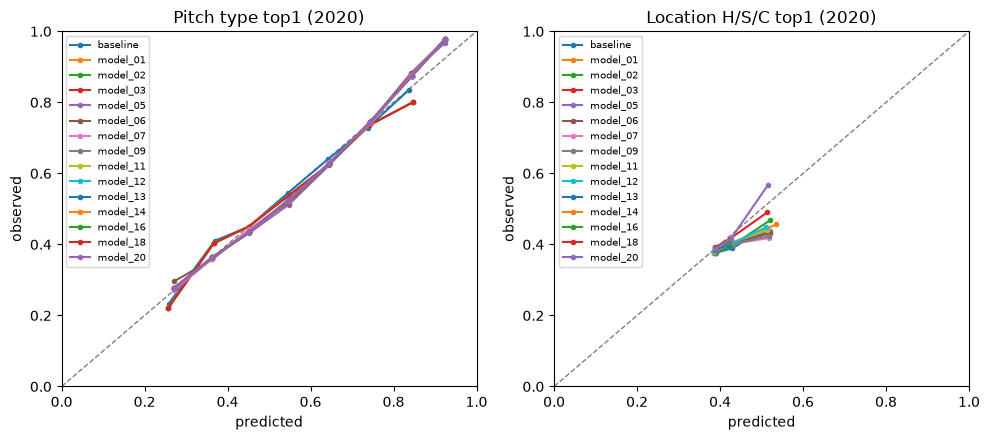

In [7]:
# 1등 예측 보정 그림 (모델 겹쳐 그리기)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, k, title in [(axes[0], 0, "Pitch type top1 (2020)"), (axes[1], 2, "Location H/S/C top1 (2020)")]:
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    for n in R:
        P, y = P20[n][k], P20[n][k + 1]
        t, _ = fc.calib(P.max(1), P.argmax(1) == y)
        t = t[t["공수"] >= 30]  # 공 30개 미만 구간 생략
        ax.plot(t["예측평균"], t["실제비율"], marker="o", ms=3, label=n)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="predicted", ylabel="observed", title=title)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 4. 분류 지표 (2020, 1등 예측)

In [8]:
tot, rec = {}, {}
for n in R:
    Pt, yt, Pg, yg = P20[n]
    rep, t, _ = fc.class_report(yt, Pt.argmax(1), fc.CLASSES)
    tg = fc.class_report(yg, Pg.argmax(1), fc.HSC)[1]
    tot[n] = {**{"구종 " + k: v for k, v in t.items()}, **{"H/S/C " + k: v for k, v in tg.items()}}
    rec[n] = rep["recall"]
display(pd.DataFrame(tot).T.round(4))
print("구종별 recall")
display(pd.DataFrame(rec).T.round(3))

,구종 accuracy,구종 balanced accuracy,구종 macro F1,H/S/C accuracy,H/S/C balanced accuracy,H/S/C macro F1
baseline,0.5244,0.2576,0.2576,0.3883,0.3362,0.2113
model_01,0.5233,0.2833,0.2857,0.3902,0.3393,0.2690
model_02,0.5233,0.2833,0.2857,0.3874,0.3370,0.2706
model_03,0.5233,0.2833,0.2857,0.3885,0.3386,0.2834
model_05,0.5306,0.3195,0.3361,0.3889,0.3390,0.2838
model_06,0.5330,0.3384,0.3496,0.3883,0.3384,0.2829
model_07,0.5340,0.3392,0.3510,0.3891,0.3391,0.2835
model_09,0.5332,0.3473,0.3545,0.3896,0.3396,0.2841
model_11,0.5332,0.3473,0.3545,0.3898,0.3398,0.2857
model_12,0.5332,0.3473,0.3545,0.3910,0.3406,0.2823


구종별 recall


,CHUP,CURV,CUTT,FAST,FORK,KNUC,SLID,TWOS
baseline,0.207,0.019,0.196,0.907,0.017,0.0,0.105,0.611
model_01,0.226,0.021,0.344,0.878,0.043,0.0,0.138,0.616
model_02,0.226,0.021,0.344,0.878,0.043,0.0,0.138,0.616
model_03,0.226,0.021,0.344,0.878,0.043,0.0,0.138,0.616
model_05,0.304,0.100,0.328,0.826,0.171,0.0,0.185,0.642
model_06,0.306,0.096,0.471,0.823,0.182,0.0,0.194,0.635
model_07,0.310,0.094,0.460,0.822,0.190,0.0,0.198,0.639
model_09,0.308,0.090,0.529,0.818,0.190,0.0,0.199,0.644
model_11,0.308,0.090,0.529,0.818,0.190,0.0,0.199,0.644
model_12,0.308,0.090,0.529,0.818,0.190,0.0,0.199,0.644


## 5. 실전 출력: 보여 주는 구종 수와 포함률 (2020)

In [9]:
rows = {}
for n in R:
    Pt, yt = P20[n][0], P20[n][1]
    i = np.arange(len(yt))
    for w, s in {"1개 고정": fc.show_types(Pt, k=1), "2개 고정": fc.show_types(Pt, k=2), "누적 80%": fc.show_types(Pt)}.items():
        rows[(n, w)] = {"보여 준 구종 수 평균": s.sum(1).mean(), "실제 구종 포함률": s[i, yt].mean(),
                        "보여 준 확률 합 평균": (Pt * s).sum(1).mean()}
display(pd.DataFrame(rows).T.round(3))

보여 준 구종 수 평균  실제 구종 포함률  보여 준 확률 합 평균
baseline 1개 고정          1.000      0.524         0.523
         2개 고정          2.000      0.811         0.805
         누적 80%         2.510      0.904         0.896
model_01 1개 고정          1.000      0.523         0.528
         2개 고정          2.000      0.816         0.818
         누적 80%         2.450      0.901         0.900
model_02 1개 고정          1.000      0.523         0.528
         2개 고정          2.000      0.816         0.818
         누적 80%         2.450      0.901         0.900
model_03 1개 고정          1.000      0.523         0.528
         2개 고정          2.000      0.816         0.818
         누적 80%         2.450      0.901         0.900
model_05 1개 고정          1.000      0.531         0.545
         2개 고정          2.000      0.821         0.823
         누적 80%         2.388      0.902         0.899
model_06 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.820         0.821
         누적 80%         2.396      0.904         0.899
model_07 1개 고정          1.000      0.534         0.543
         2개 고정          2.000      0.821         0.821
         누적 80%         2.395      0.904         0.899
model_09 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.822         0.822
         누적 80%         2.391      0.905         0.899
model_11 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.822         0.822
         누적 80%         2.391      0.905         0.899
model_12 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.822         0.822
         누적 80%         2.391      0.905         0.899
model_13 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.822         0.822
         누적 80%         2.391      0.905         0.899
model_14 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.822         0.822
         누적 80%         2.391      0.905         0.899
model_16 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.822         0.822
         누적 80%         2.391      0.905         0.899
model_18 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.822         0.822
         누적 80%         2.391      0.905         0.899
model_20 1개 고정          1.000      0.533         0.544
         2개 고정          2.000      0.822         0.822
         누적 80%         2.391      0.905         0.899